# China: cobertura, procedencia y límites de comparación

La tabla larga conserva observaciones publicadas, estimaciones y candidatas en cuarentena. La vista anual excluye niveles de escala pendiente y años 2026+. No hay interpolación ni empalmes. Los índices de demanda PWT cancelan la escala constante, pero no resuelven por sí solos diferencias de universo.

Instrucciones originales: `datos/bronze/professor_instructions_20261021/`. Contratos, decisiones y trazabilidad: `output/revision_china/`. El periodo 1960–2023 es obligatorio en el tema 7; los demás apartados usan la cobertura observada y explicitan sus límites.

In [1]:
from pathlib import Path
import json
import polars as pl
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/'datos').exists() else Path.cwd().parent
OUT = ROOT/'output/revision_china'
FIG = OUT/'figuras'; FIG.mkdir(exist_ok=True)
d = pl.read_parquet(ROOT/'datos/silver/china.parquet')
catalogue = pl.read_csv(OUT/'catalogo_china.csv', infer_schema_length=None)
contracts = pl.read_csv(OUT/'contratos.csv', infer_schema_length=None)
def show(fig, name):
    fig.tight_layout(); fig.savefig(FIG/(name+'.png'), dpi=140, bbox_inches='tight'); plt.close(fig)
    display(Image(filename=str(FIG/(name+'.png'))))
display(pl.read_json(OUT/'quality.json').select('status','observations','series','analytic_series'))
display(contracts.select('concept','status','first','last','n'))

/home/xylon/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-kygfz9zs because there was an issue with the default path (/home/xylon/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


status,observations,series,analytic_series
str,i64,i64,i64
"""OK_WITH_DOCUMENTED_GAPS""",7514,136,90


concept,status,first,last,n
str,str,i64,i64,i64
"""gdp_nominal""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2025,66
"""gdp_real""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2025,66
"""c_nominal""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2024,65
"""c_real""","""CANDIDATA_EN_CUARENTENA""",1952,2023,72
"""g_nominal""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2024,65
…,…,…,…,…
"""unemployment""","""ALTERNATIVA_DOCUMENTADA""",1991,2027,37
"""registered_unemployment""","""ALTERNATIVA_NBS_COBERTURA_LIMI…",2020,2024,5
"""survey_unemployment""","""ALTERNATIVA_DOCUMENTADA""",2016,2022,7


## Cobertura: no es un panel equilibrado
Las series de trabajo publicadas por OIT se mantienen separadas por fuente. PWT aporta el tramo largo para crecimiento; eso no convierte empleo PWT en EPA. Las candidatas monetarias NA y de capital conservan los valores originales fuera de la vista analítica.

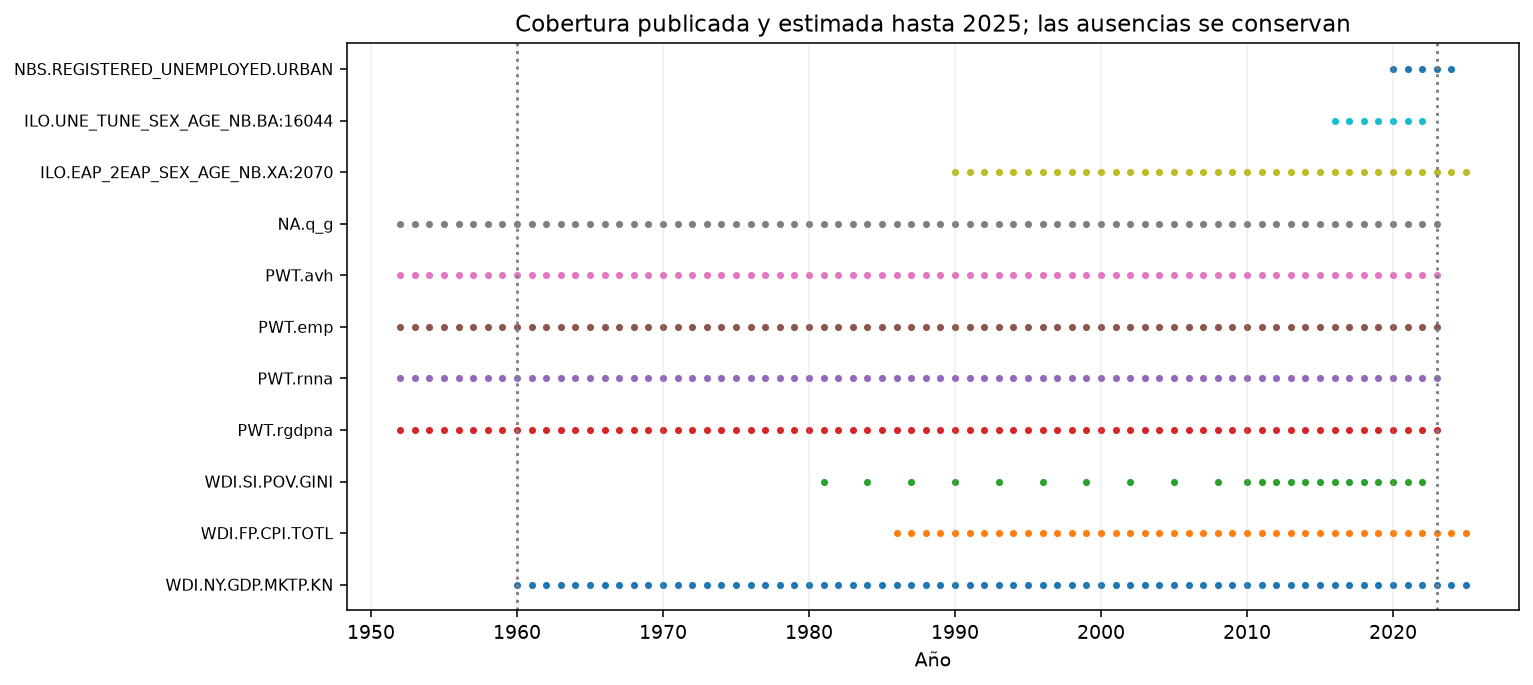

In [2]:
keys=['WDI.NY.GDP.MKTP.KN','WDI.FP.CPI.TOTL','WDI.SI.POV.GINI','PWT.rgdpna','PWT.rnna','PWT.emp','PWT.avh','NA.q_g','ILO.EAP_2EAP_SEX_AGE_NB.XA:2070','ILO.UNE_TUNE_SEX_AGE_NB.BA:16044','NBS.REGISTERED_UNEMPLOYED.URBAN']
fig,ax=plt.subplots(figsize=(11,5))
for i,s in enumerate(keys):
    z=d.filter((pl.col('series_id')==s)&(pl.col('year')<=2025))
    ax.scatter(z['year'],[i]*z.height,s=7)
ax.set_yticks(range(len(keys)),keys,fontsize=8);ax.set(xlabel='Año',title='Cobertura publicada y estimada hasta 2025; las ausencias se conservan')
ax.axvline(1960,color='gray',ls=':');ax.axvline(2023,color='gray',ls=':');ax.grid(axis='x',alpha=.2)
show(fig,'01_cobertura')

## Concordancia de fuentes no equivale a validación independiente
NBS y WDI pueden distribuir la misma medición nacional. PWT 11 utiliza PIB oficial para CHN; Wu/CH2 permanece como sensibilidad separada en la revisión previa. La comparación PWT NA prueba una hipótesis de escala, sin alterar los niveles archivados. Las diferencias pueden reflejar ediciones y revisiones; aquí no se atribuyen automáticamente a una causa única.

comparison,n,max_abs_relative_pct,median_relative_pct
str,i64,f64,f64
"""NBS_GDP_vs_PWT_NA_scale_hypoth…",46,2.672543,1.096506
"""NBS_GDP_vs_WDI""",47,0.363117,0.0
"""NBS_M2_vs_WDI_broad_money""",35,5.562738,0.00682


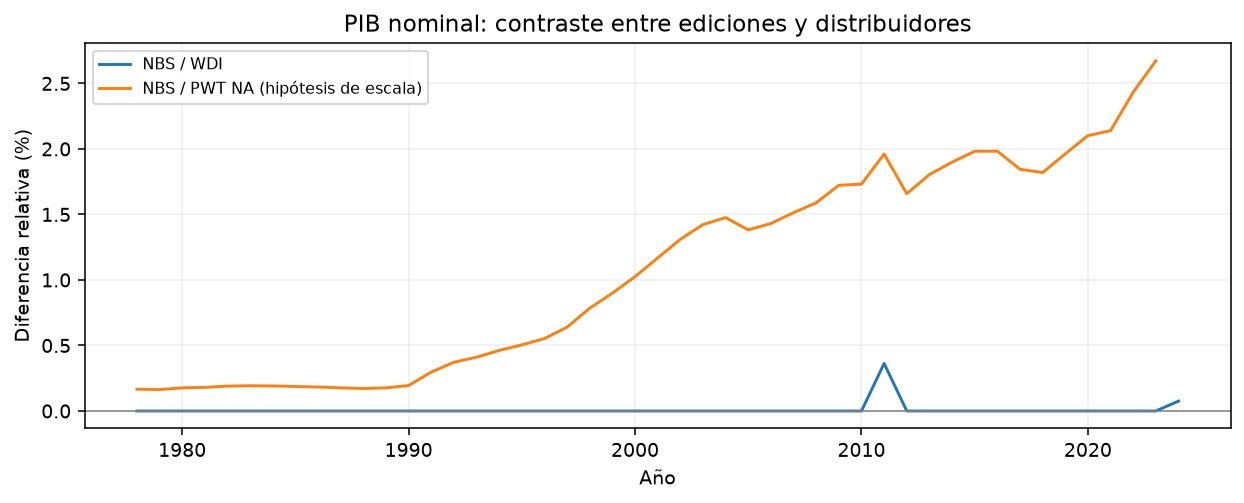

In [3]:
comparisons=pl.read_csv(OUT/'source_comparisons.csv')
display(pl.read_csv(OUT/'source_comparison_summary.csv'))
fig,ax=plt.subplots(figsize=(9,3.7))
for comparison,label in [('NBS_GDP_vs_WDI','NBS / WDI'),('NBS_GDP_vs_PWT_NA_scale_hypothesis','NBS / PWT NA (hipótesis de escala)')]:
    z=comparisons.filter(pl.col('comparison')==comparison).sort('year')
    ax.plot(z['year'],z['relative_difference_pct'],label=label)
ax.axhline(0,color='gray',lw=.8);ax.set(xlabel='Año',ylabel='Diferencia relativa (%)',title='PIB nominal: contraste entre ediciones y distribuidores');ax.legend(fontsize=8);ax.grid(alpha=.2)
show(fig,'02_contraste_pib')

## Demanda real: explorar índices, conservar las reservas conceptuales
WDI no publica valores para G, FBCF, X e IM reales en las consultas archivadas. PWT NA ofrece candidatas, con escala monetaria no acreditada por la leyenda. Se muestran índices calculados dentro de cada serie. No se suman volúmenes ni se obtiene variación de existencias por diferencia. Inversión PWT y FBC no quedan certificadas como equivalentes por el nombre.

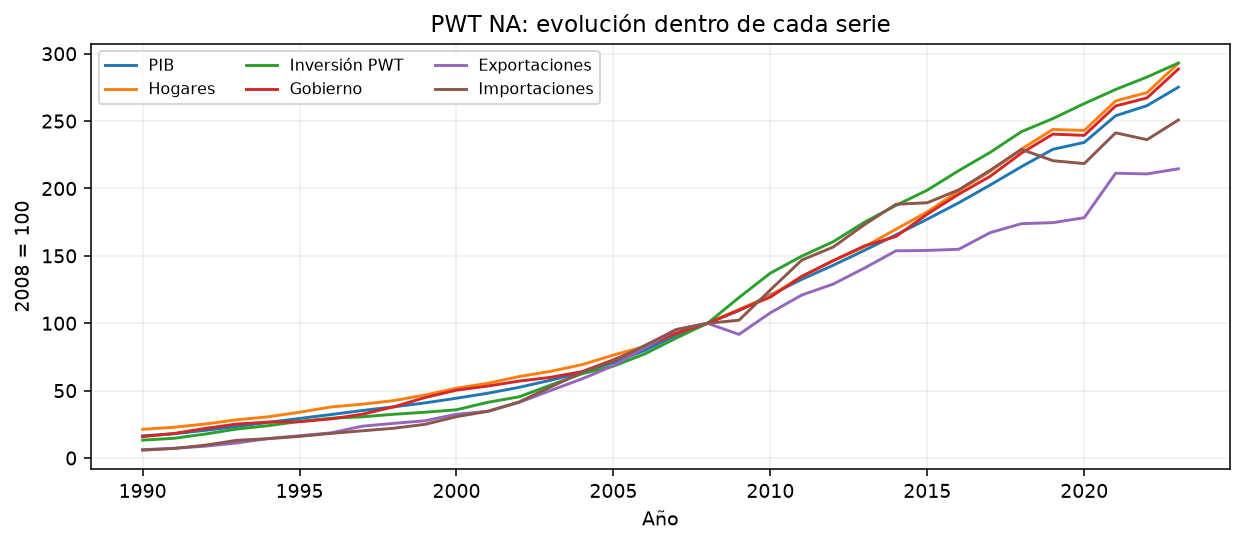

In [4]:
fig,ax=plt.subplots(figsize=(9,4))
for var,label in [('q_gdp','PIB'),('q_c','Hogares'),('q_i','Inversión PWT'),('q_g','Gobierno'),('q_x','Exportaciones'),('q_m','Importaciones')]:
    z=d.filter((pl.col('series_id')=='INDEX.NA.'+var)&pl.col('year').is_between(1990,2023)).sort('year')
    ax.plot(z['year'],z['value'],label=label)
ax.set(xlabel='Año',ylabel='2008 = 100',title='PWT NA: evolución dentro de cada serie');ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.2)
show(fig,'03_demanda_indices')

## Mercado laboral: comparar fuentes sin empalmarlas
Los niveles modelizados OIT usan miles de personas de 15+; encuesta, estimaciones oficiales y censo son series diferentes. El paro registrado NBS es urbano y el momento de referencia no consta en la fila: no se transforma en media anual ni se une al desempleo nacional de encuesta. Las tasas urbanas media y diciembre se conservan separadas. Las proyecciones OIT 2026+ no entran en la vista analítica.

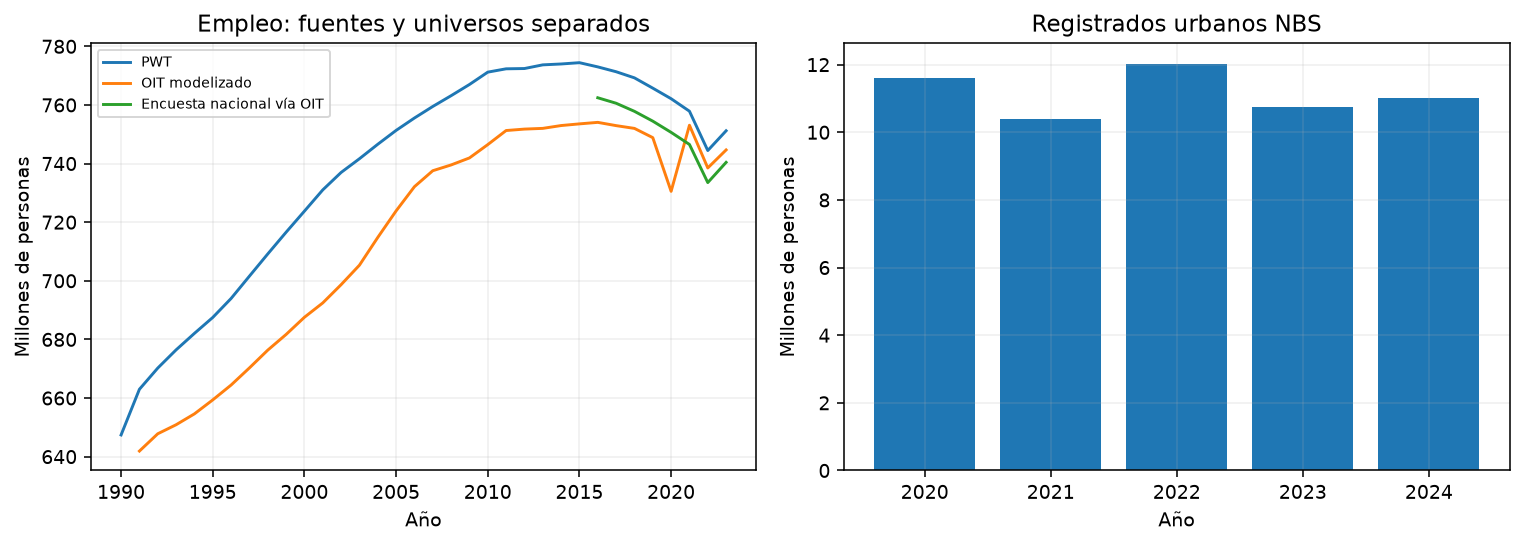

residual_thousand
f64
0.001


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for sid,label,scale in [('PWT.emp','PWT',1),('ILO.EMP_2EMP_SEX_AGE_NB.XA:2070','OIT modelizado',.001),('ILO.EMP_TEMP_SEX_AGE_NB.BA:16044','Encuesta nacional vía OIT',.001)]:
    z=d.filter((pl.col('series_id')==sid)&pl.col('year').is_between(1990,2023)).sort('year')
    axes[0].plot(z['year'],z['value']*scale,label=label)
axes[0].set(title='Empleo: fuentes y universos separados',ylabel='Millones de personas',xlabel='Año');axes[0].legend(fontsize=7)
z=d.filter(pl.col('series_id')=='NBS.REGISTERED_UNEMPLOYED.URBAN').sort('year')
axes[1].bar(z['year'],z['value']/100);axes[1].set(title='Registrados urbanos NBS',ylabel='Millones de personas',xlabel='Año')
for ax in axes:ax.grid(alpha=.2)
show(fig,'04_laboral')
display(pl.read_csv(OUT/'ilo_identity.csv').select(pl.col('residual_thousand').abs().max()))

## Input-output: productos oferentes en filas y usuarios en columnas
La matriz 20×20 se agrega a agricultura (producto 1), industria incluida construcción (2–12) y servicios (13–20). Las 400 celdas se transcribieron del JPG y se contrastaron con los 40 totales publicados, permitiendo solo el redondeo de celdas a una decimal. La imagen no explicita escala: se preservan unidades nativas, sin certificar niveles monetarios. Es un año estructural a precios de productor, no una serie de PIB a precios de mercado.

supplying_sector,using_sector,value,unit
str,str,f64,str
"""agriculture""","""agriculture""",22600.7,"""native_IO_table_unit_scale_not…"
"""agriculture""","""industry""",61212.6,"""native_IO_table_unit_scale_not…"
"""agriculture""","""services""",17726.0,"""native_IO_table_unit_scale_not…"
"""industry""","""agriculture""",31845.1,"""native_IO_table_unit_scale_not…"
"""industry""","""industry""",1025705.7,"""native_IO_table_unit_scale_not…"
"""industry""","""services""",213342.5,"""native_IO_table_unit_scale_not…"
"""services""","""agriculture""",10102.5,"""native_IO_table_unit_scale_not…"
"""services""","""industry""",267178.4,"""native_IO_table_unit_scale_not…"
"""services""","""services""",430783.7,"""native_IO_table_unit_scale_not…"


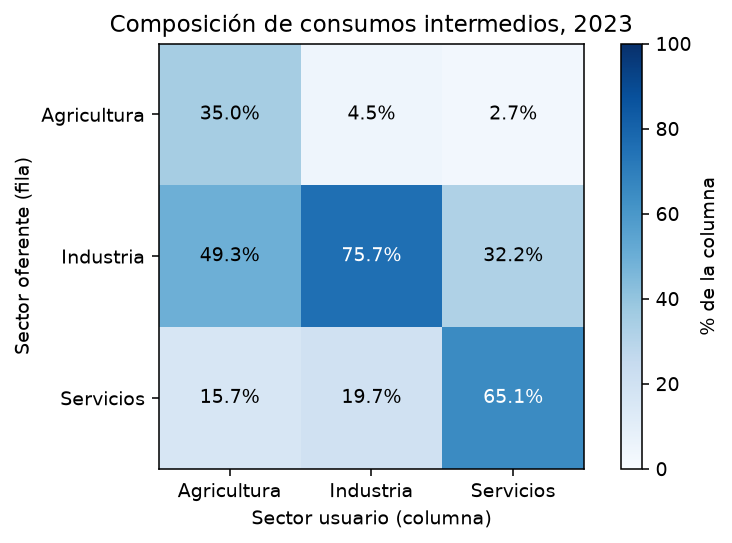

In [6]:
io=pl.read_csv(OUT/'io_2023_3_sectors.csv');display(io.select('supplying_sector','using_sector','value','unit'))
fig,ax=plt.subplots(figsize=(6,4))
names=['agriculture','industry','services']
a=[[io.filter((pl.col('supplying_sector')==i)&(pl.col('using_sector')==j))['value'][0] for j in names] for i in names]
import numpy as np
a=np.array(a);shares=a/a.sum(axis=0)*100
im=ax.imshow(shares,cmap='Blues',vmin=0,vmax=100)
ax.set_xticks(range(3),['Agricultura','Industria','Servicios']);ax.set_yticks(range(3),['Agricultura','Industria','Servicios'])
for i in range(3):
    for j in range(3):ax.text(j,i,f'{shares[i,j]:.1f}%',ha='center',va='center',color='white' if shares[i,j]>50 else 'black')
ax.set(xlabel='Sector usuario (columna)',ylabel='Sector oferente (fila)',title='Composición de consumos intermedios, 2023');fig.colorbar(im,ax=ax,label='% de la columna')
show(fig,'05_io')

## Crecimiento 1960–2023 y Gini observado
La descomposición usa PIB, capital y empleo de PWT, α=1/3 y diferencias logarítmicas anualizadas. Los subperiodos son los mismos para los temas 6 y 7; el residuo no identifica exclusivamente tecnología. Las comparaciones de bienestar requieren PIB en PPA; aquí se representa Gini solo en años publicados, sin completar huecos ni acreditar el mismo concepto distributivo que España.

start,end,gdp_log_growth,capital_contribution,employment_contribution,solow_residual,alpha,n_years,note
i64,i64,f64,f64,f64,f64,f64,i64,str
1960,1989,6.12822,2.18677,1.742164,2.199286,0.333333,30,"""Mismos periodos temas 6–7; res…"
1989,2000,9.366573,3.144065,0.86438,5.358128,0.333333,12,"""Mismos periodos temas 6–7; res…"
2000,2008,10.153765,3.790035,0.441601,5.922129,0.333333,9,"""Mismos periodos temas 6–7; res…"
2008,2019,7.534699,3.61899,0.0204,3.895309,0.333333,12,"""Mismos periodos temas 6–7; res…"
2019,2023,4.587205,2.485681,-0.319634,2.421157,0.333333,5,"""Mismos periodos temas 6–7; res…"
1960,2023,7.35256,2.826554,0.992216,3.53379,0.333333,64,"""Mismos periodos temas 6–7; res…"


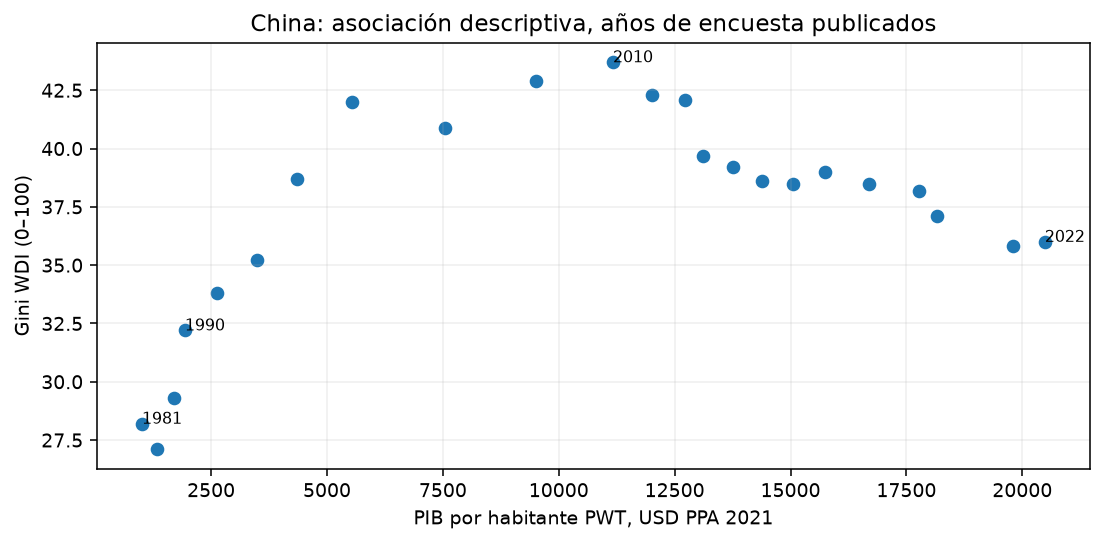

In [7]:
display(pl.read_csv(OUT/'growth_accounting_1960_2023.csv'))
y=d.filter(pl.col('series_id')=='DER.gdp_pc_ppp').select('year',pl.col('value').alias('gdp_pc_ppp'))
g=d.filter(pl.col('series_id')=='WDI.SI.POV.GINI').select('year',pl.col('value').alias('gini'))
z=y.join(g,on='year').sort('year')
fig,ax=plt.subplots(figsize=(8,4));ax.scatter(z['gdp_pc_ppp'],z['gini'])
for r in z.iter_rows(named=True):
    if r['year'] in [1981,1990,2000,2010,2022]:ax.annotate(str(r['year']),(r['gdp_pc_ppp'],r['gini']),fontsize=8)
ax.set(xlabel='PIB por habitante PWT, USD PPA 2021',ylabel='Gini WDI (0–100)',title='China: asociación descriptiva, años de encuesta publicados');ax.grid(alpha=.2)
show(fig,'06_gini')

## Decisiones pendientes y uso
Consultar `CIERRE_CHINA.md` y `contratos.csv`. No se autoriza a unir automáticamente las alternativas. Siguen pendientes series anuales acreditadas de CCF real, existencias reales, EBE, coste de factores y D2/D3 separados. Producción/consumos intermedios e input-output solo tienen evidencia estructural de 2023; remuneración NBS solo 2023; la escala de NA/CAP y de la tabla IO requiere documentación adicional. El catálogo español completo sigue incluido en la matriz de correspondencias, con las variables complementarias sin equivalencia distinguidas del núcleo docente.